In [2]:
import os
from pathlib import Path
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import transforms, datasets
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
# Optimized for Google Colab - reduced batch size and image size
BATCH_SIZE = 64  # Reduced for Colab (can increase to 32 if you have Colab Pro)
IMAGE_SIZE = (224, 224)  # Reduced from 299 to 224 for Colab (faster, less memory)
N_CLASSES = 21  # UC Merced has 21 land-use classes
DATA_ROOT = Path("data/uc_merced")
IMAGES_ROOT = DATA_ROOT / "Images"
LEARNING_RATE = 0.01  # Paper: learning rate 0.01

# Colab optimizations - detect if running on Google Colab
try:
    import google.colab
    IS_COLAB = True
except ImportError:
    IS_COLAB = 'COLAB' in os.environ or 'google.colab' in str(Path.cwd())
if IS_COLAB:
    print("✓ Running on Google Colab - applying optimizations...")

# Enable cuDNN/matmul autotuning when using GPU for maximum performance
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    try:
        torch.set_float32_matmul_precision("medium")
    except AttributeError:
        pass
    # Clear GPU cache for Colab
    torch.cuda.empty_cache()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Using device: {DEVICE}")


✓ Running on Google Colab - applying optimizations...
Using device: cuda


/usr/local/lib/python3.12/dist-packages/torch/__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


In [3]:
import shutil
import kagglehub


def prepare_uc_merced(root: Path = DATA_ROOT, images_root: Path = IMAGES_ROOT) -> Path:
    """Download UC Merced dataset via kagglehub and copy Images folder to project data dir.

    Kaggle dataset: abdulhasibuddin/uc-merced-land-use-dataset
    We search for an "Images" directory inside the downloaded path and copy it.
    """
    root.mkdir(parents=True, exist_ok=True)

    # If images already prepared, just return
    if images_root.exists() and any(images_root.glob("*/*")):
        print(f"UC Merced images already available at {images_root}")
        return images_root

    print("Downloading UC Merced Land Use dataset via kagglehub...")
    dataset_path = Path(kagglehub.dataset_download("abdulhasibuddin/uc-merced-land-use-dataset"))
    print("Kaggle dataset cached at:", dataset_path)

    # Find the Images directory (it may be nested)
    candidates = [p for p in dataset_path.rglob("Images") if p.is_dir()]
    if not candidates:
        raise FileNotFoundError(f"Could not find an 'Images' directory under {dataset_path}")

    src_images = candidates[0]
    print("Found Images directory:", src_images)

    if not images_root.exists():
        print(f"Copying {src_images} -> {images_root} (one-time operation)...")
        shutil.copytree(src_images, images_root)
    else:
        print(f"Images root {images_root} already exists.")

    print("UC Merced dataset ready.")
    return images_root


images_path = prepare_uc_merced()
print("Number of class folders:", len(list(images_path.iterdir())))


Using Colab cache for faster access to the 'uc-merced-land-use-dataset' dataset.
Kaggle dataset cached at: /kaggle/input/uc-merced-land-use-dataset
Found Images directory: /kaggle/input/uc-merced-land-use-dataset/UCMerced_LandUse/Images
Copying /kaggle/input/uc-merced-land-use-dataset/UCMerced_LandUse/Images -> data/uc_merced/Images (one-time operation)...
UC Merced dataset ready.
Number of class folders: 21


Total number of images: 2100
Number of classes: 21

Class names: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']

Data Split Summary:
Training set: 1680 images (80.0%)
Test set: 420 images (20.0%)

Training set distribution per class:
  agricultural             :  87 images
  airplane                 :  68 images
  baseballdiamond          :  81 images
  beach                    :  77 images
  buildings                :  74 images
  chaparral                :  82 images
  denseresidential         :  81 images
  forest                   :  86 images
  freeway                  :  81 images
  golfcourse               :  76 images
  harbor                   :  80 images
  intersection             :  77 images
  mediumresidential        :  86 

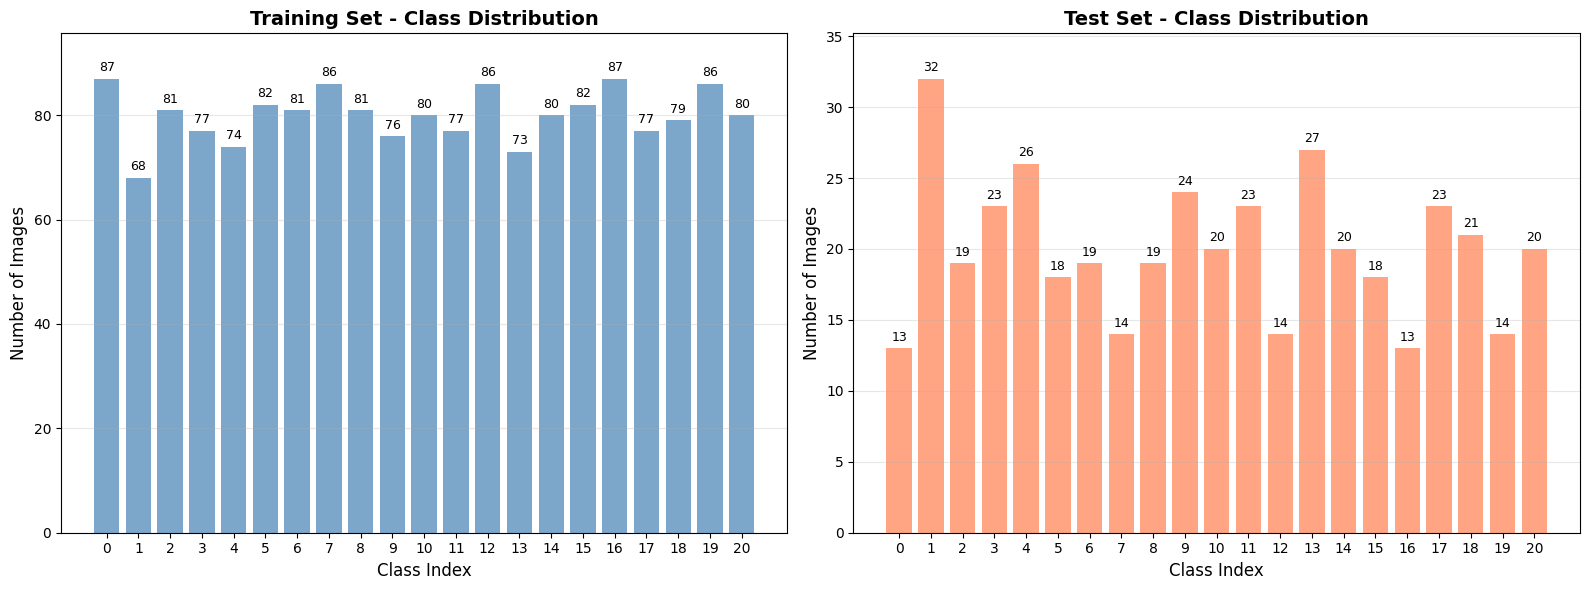


Distribution Statistics:
Training set - Min: 68, Max: 87, Mean: 80.0, Std: 4.8
Test set - Min: 13, Max: 32, Mean: 20.0, Std: 4.8


In [4]:
# Data Splitting and Distribution Analysis
# According to the article: 80% training, 20% evaluation (test)

from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# Load dataset without transforms for analysis
base_dataset_for_analysis = datasets.ImageFolder(IMAGES_ROOT, transform=None)
class_names = base_dataset_for_analysis.classes

print(f"Total number of images: {len(base_dataset_for_analysis)}")
print(f"Number of classes: {len(class_names)}")
print(f"\nClass names: {class_names}")

# Split data: 80% training, 20% evaluation (test)
num_samples = len(base_dataset_for_analysis)
num_train = int(0.8 * num_samples)
num_test = num_samples - num_train

# Create indices and shuffle with fixed seed for reproducibility
indices = list(range(num_samples))
random.Random(SEED).shuffle(indices)

train_indices = indices[:num_train]
test_indices = indices[num_train:]

# Get labels for training and test sets
train_labels = [base_dataset_for_analysis.targets[i] for i in train_indices]
test_labels = [base_dataset_for_analysis.targets[i] for i in test_indices]

# Count distribution for each class
train_distribution = Counter(train_labels)
test_distribution = Counter(test_labels)

print(f"\n{'='*60}")
print(f"Data Split Summary:")
print(f"{'='*60}")
print(f"Training set: {num_train} images ({num_train/num_samples*100:.1f}%)")
print(f"Test set: {num_test} images ({num_test/num_samples*100:.1f}%)")
print(f"\nTraining set distribution per class:")
for class_idx in sorted(train_distribution.keys()):
    class_name = class_names[class_idx]
    count = train_distribution[class_idx]
    print(f"  {class_name:25s}: {count:3d} images")
print(f"\nTest set distribution per class:")
for class_idx in sorted(test_distribution.keys()):
    class_name = class_names[class_idx]
    count = test_distribution[class_idx]
    print(f"  {class_name:25s}: {count:3d} images")

# Draw histogram of data distribution for each class
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Training set histogram
train_counts = [train_distribution[i] for i in range(len(class_names))]
axes[0].bar(range(len(class_names)), train_counts, color='steelblue', alpha=0.7)
axes[0].set_xlabel('Class Index', fontsize=12)
axes[0].set_ylabel('Number of Images', fontsize=12)
axes[0].set_title('Training Set - Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_xticks(range(len(class_names)))
axes[0].set_xticklabels(range(len(class_names)), rotation=0)
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, max(train_counts) * 1.1])

# Add value labels on bars
for i, count in enumerate(train_counts):
    axes[0].text(i, count + max(train_counts)*0.01, str(count),
                ha='center', va='bottom', fontsize=9)

# Test set histogram
test_counts = [test_distribution[i] for i in range(len(class_names))]
axes[1].bar(range(len(class_names)), test_counts, color='coral', alpha=0.7)
axes[1].set_xlabel('Class Index', fontsize=12)
axes[1].set_ylabel('Number of Images', fontsize=12)
axes[1].set_title('Test Set - Class Distribution', fontsize=14, fontweight='bold')
axes[1].set_xticks(range(len(class_names)))
axes[1].set_xticklabels(range(len(class_names)), rotation=0)
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim([0, max(test_counts) * 1.1])

# Add value labels on bars
for i, count in enumerate(test_counts):
    axes[1].text(i, count + max(test_counts)*0.01, str(count),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Summary statistics
print(f"\n{'='*60}")
print(f"Distribution Statistics:")
print(f"{'='*60}")
print(f"Training set - Min: {min(train_counts)}, Max: {max(train_counts)}, Mean: {np.mean(train_counts):.1f}, Std: {np.std(train_counts):.1f}")
print(f"Test set - Min: {min(test_counts)}, Max: {max(test_counts)}, Mean: {np.mean(test_counts):.1f}, Std: {np.std(test_counts):.1f}")

# Store split indices for later use (already lists)
train_split_indices = train_indices
test_split_indices = test_indices


Visualizing data augmentation for class: 'airplane'
Showing 2 sample image(s) with 6 augmentation variants each



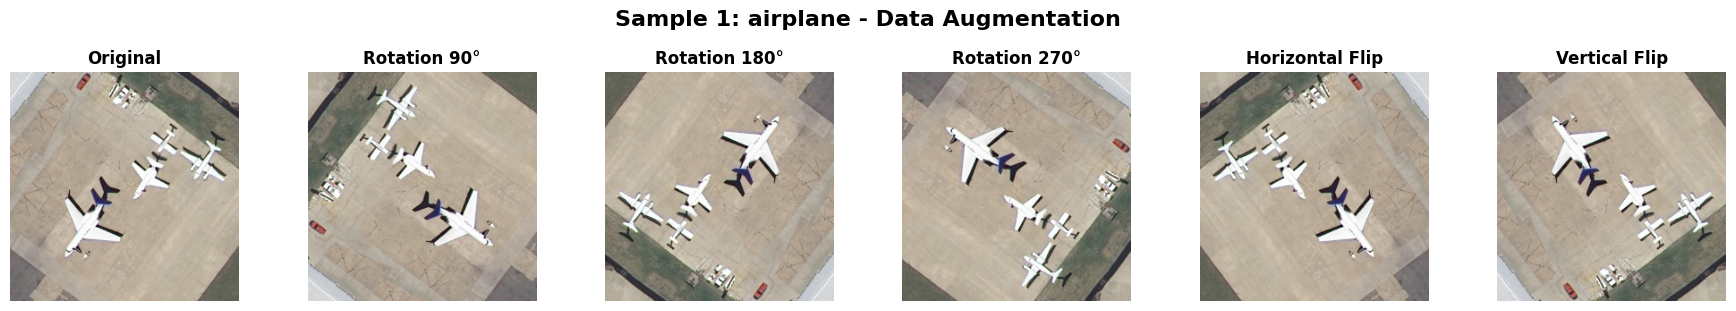

  ✓ Displayed augmentation variants for image 1/2


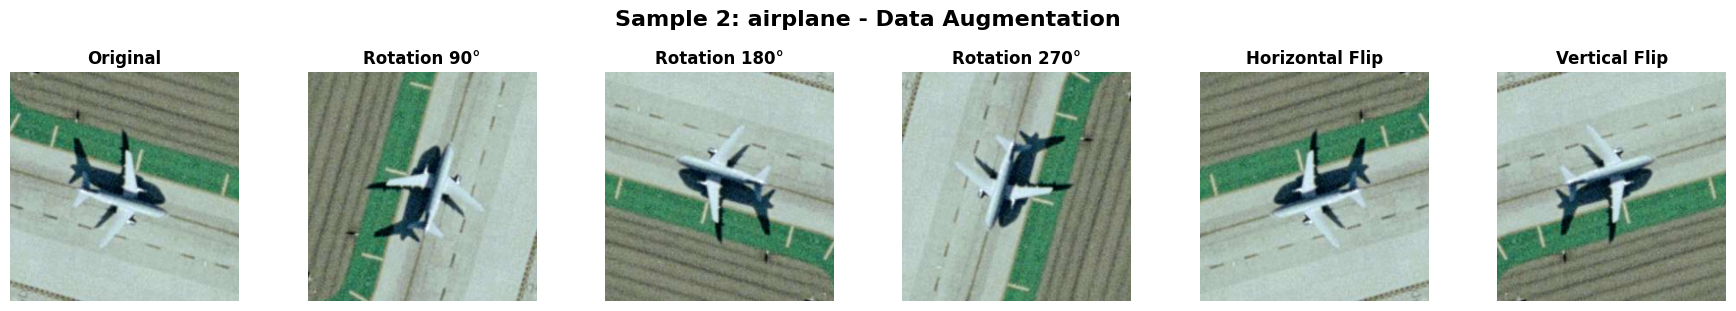

  ✓ Displayed augmentation variants for image 2/2


In [5]:
# Visualize Data Augmentation - Display original and augmented images
# Similar to Figure 7 of the article

from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from torchvision import transforms

# Load class names if not already loaded
if 'class_names' not in globals():
    temp_dataset = datasets.ImageFolder(IMAGES_ROOT, transform=None)
    class_names = temp_dataset.classes
    print(f"Loaded {len(class_names)} classes: {class_names}")

def visualize_augmentation(class_name='airplane', num_images=3):
    """
    Select images from a specific class and display original + all augmented versions.

    Args:
        class_name: Name of the class to visualize (e.g., 'airplane', 'agricultural', etc.)
        num_images: Number of sample images to show
    """
    # Check if class exists
    if class_name not in class_names:
        print(f"Class '{class_name}' not found. Available classes:")
        print(class_names)
        # Use first available class
        class_name = class_names[0]
        print(f"\nUsing '{class_name}' instead.")

    class_idx = class_names.index(class_name)
    class_folder = IMAGES_ROOT / class_name

    # Get all images from this class
    image_files = sorted(list(class_folder.glob("*.tif")))
    if len(image_files) == 0:
        image_files = sorted(list(class_folder.glob("*.jpg")))

    if len(image_files) == 0:
        print(f"No images found in {class_folder}")
        return

    # Select desired number of images
    num_images = min(num_images, len(image_files))
    selected_images = image_files[:num_images]

    print(f"Visualizing data augmentation for class: '{class_name}'")
    print(f"Showing {num_images} sample image(s) with 6 augmentation variants each\n")

    # Define augmentation types (matching paper's augmentation)
    augmentation_types = [
        ("Original", None),
        ("Rotation 90°", lambda img: transforms.functional.rotate(img, 90)),
        ("Rotation 180°", lambda img: transforms.functional.rotate(img, 180)),
        ("Rotation 270°", lambda img: transforms.functional.rotate(img, 270)),
        ("Horizontal Flip", lambda img: transforms.functional.hflip(img)),
        ("Vertical Flip", lambda img: transforms.functional.vflip(img)),
    ]

    # Create figure for each selected image
    for img_idx, img_path in enumerate(selected_images):
        # Load original image
        original_img = Image.open(img_path).convert('RGB')

        # Create subplot: 1 row × 6 columns (original + 5 augmentations)
        fig, axes = plt.subplots(1, 6, figsize=(18, 3))
        fig.suptitle(f'Sample {img_idx + 1}: {class_name} - Data Augmentation',
                     fontsize=16, fontweight='bold', y=1.02)

        for aug_idx, (aug_name, aug_func) in enumerate(augmentation_types):
            if aug_func is None:
                # Original image
                img = original_img
            else:
                # Apply augmentation
                img = aug_func(original_img)

            # Display image
            axes[aug_idx].imshow(img)
            axes[aug_idx].set_title(aug_name, fontsize=12, fontweight='bold')
            axes[aug_idx].axis('off')

        plt.tight_layout()
        plt.show()
        print(f"  ✓ Displayed augmentation variants for image {img_idx + 1}/{num_images}")

# Visualize augmentation for a specific class
# You can change 'airplane' to any other class name from the dataset
# Available classes: agricultural, airplane, baseballfield, beach, buildings,
#                    chaparral, denseresidential, forest, freeway, golfcourse,
#                    harbor, intersection, mediumresidential, mobilehomepark,
#                    overpass, parkinglot, river, runway, sparseresidential,
#                    storagetanks, tenniscourt

visualize_augmentation(class_name='airplane', num_images=2)


In [6]:
from collections import Counter
from PIL import Image
import torch.utils.data as data

# Optimized data augmentation for Colab - reduced from 6× to 3× for lighter training
# Paper uses 6× (original + 5 augmentations), but we use 3× for Colab efficiency
class AugmentedDataset(data.Dataset):
    """Dataset that applies paper-style augmentation on-the-fly: rotations, horizontal/vertical flips."""
    def __init__(self, base_dataset, original_dataset, augment=True, deterministic=False, aug_multiplier=3):
        self.base_dataset = base_dataset  # random_split subset
        self.original_dataset = original_dataset  # full ImageFolder dataset
        self.augment = augment
        self.deterministic = deterministic
        self.aug_multiplier = aug_multiplier  # 3 for Colab (lighter), 6 for full paper implementation

    def __len__(self):
        if self.augment:
            # Return aug_multiplier× length (3× for Colab, 6× for full paper)
            return len(self.base_dataset) * self.aug_multiplier
        return len(self.base_dataset)

    def __getitem__(self, idx):
        if self.augment:
            base_idx = idx // self.aug_multiplier
            aug_type = idx % self.aug_multiplier

            # Get the actual index in the original dataset
            actual_idx = self.base_dataset.indices[base_idx]
            # Get image path and label from original dataset
            img_path, label = self.original_dataset.samples[actual_idx]
            img_pil = Image.open(img_path).convert('RGB')

            # Apply one of the augmentations (optimized for Colab: 3 types instead of 6)
            if aug_type == 0:
                # Original image
                pass
            elif aug_type == 1:
                # Rotation 90 degrees
                img_pil = transforms.functional.rotate(img_pil, 90)
            elif aug_type == 2:
                # Horizontal flip
                img_pil = transforms.functional.hflip(img_pil)
            # For full 6× augmentation, uncomment below:
            # elif aug_type == 3:
            #     img_pil = transforms.functional.rotate(img_pil, 180)
            # elif aug_type == 4:
            #     img_pil = transforms.functional.rotate(img_pil, 270)
            # elif aug_type == 5:
            #     img_pil = transforms.functional.vflip(img_pil)

            # Apply base transforms (resize, to tensor, normalize)
            img = base_transforms(img_pil)
            return img, label
        else:
            # For validation: get image and apply val_transforms
            actual_idx = self.base_dataset.indices[idx]
            img_path, label = self.original_dataset.samples[actual_idx]
            img_pil = Image.open(img_path).convert('RGB')
            img = val_transforms(img_pil)
            return img, label

# Base transforms (resize + normalize only) - applied after augmentation
base_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # ImageNet stats
])

val_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Load base dataset WITHOUT transforms (we'll apply them in AugmentedDataset)
base_dataset = datasets.ImageFolder(IMAGES_ROOT, transform=None)
class_names = base_dataset.classes
print("Classes ({}):".format(len(class_names)))
print(class_names)

# Train/validation split 80/20 (on original images)
num_samples = len(base_dataset)
num_train = int(0.8 * num_samples)
num_val = num_samples - num_train

train_base, val_base = random_split(base_dataset, [num_train, num_val])

# Apply optimized augmentation for Colab (3× instead of 6× for lighter training)
# Change aug_multiplier=6 for full paper implementation
aug_multiplier = 3 if IS_COLAB else 6
train_dataset = AugmentedDataset(train_base, base_dataset, augment=True, aug_multiplier=aug_multiplier)
val_dataset = AugmentedDataset(val_base, base_dataset, augment=False)

print(f"Augmentation multiplier: {aug_multiplier}× (3× for Colab, 6× for full paper)")

# Note: Validation dataset will use val_transforms in __getitem__

pin_memory = True if DEVICE.type == "cuda" else False
# Colab: use 0 workers (Colab has issues with multiple workers)
# Local: can use 1-2 workers
num_workers = 0 if IS_COLAB else (1 if DEVICE.type == "cuda" else 0)
print(f"DataLoader num_workers: {num_workers} (0 for Colab compatibility)")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory
)

print(f"Original images: {num_samples} | Train base: {num_train} | Val: {num_val}")
print(f"After augmentation: Train: {len(train_dataset)} images ({aug_multiplier}× augmented)")

# Class distribution
train_labels = [base_dataset.targets[i] for i in train_base.indices]
val_labels = [base_dataset.targets[i] for i in val_base.indices]

print("Train distribution (base):", Counter(train_labels))
print("Val distribution:", Counter(val_labels))


Classes (21):
['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']
Augmentation multiplier: 3× (3× for Colab, 6× for full paper)
DataLoader num_workers: 0 (0 for Colab compatibility)
Original images: 2100 | Train base: 1680 | Val: 420
After augmentation: Train: 5040 images (3× augmented)
Train distribution (base): Counter({18: 87, 1: 86, 4: 85, 6: 84, 10: 83, 16: 82, 14: 82, 2: 82, 17: 82, 5: 80, 11: 79, 13: 79, 8: 78, 0: 78, 9: 78, 15: 78, 7: 78, 3: 77, 20: 76, 12: 75, 19: 71})
Val distribution: Counter({19: 29, 12: 25, 20: 24, 3: 23, 9: 22, 8: 22, 7: 22, 15: 22, 0: 22, 11: 21, 13: 21, 5: 20, 16: 18, 2: 18, 14: 18, 17: 18, 10: 17, 6: 16, 4: 15, 1: 14, 18: 13})


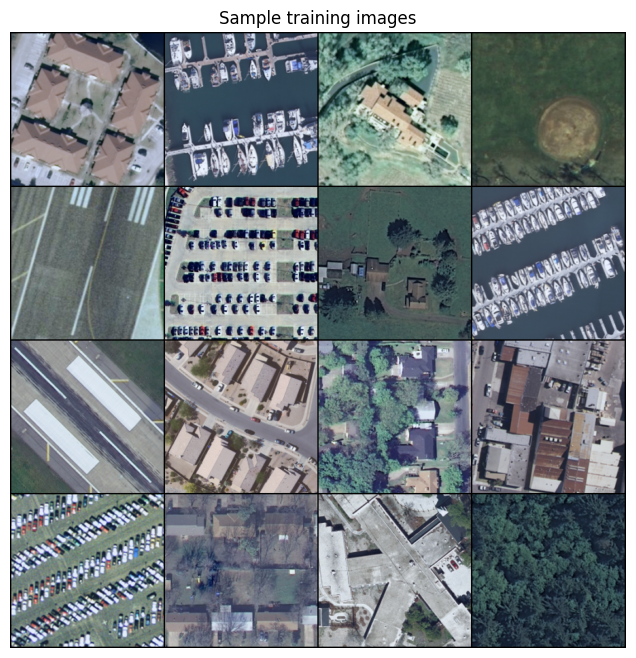

In [7]:
# Optional: visualize a small batch of training images

def show_batch(loader, class_names, n_images=16):
    batch, labels = next(iter(loader))
    batch = batch[:n_images]
    labels = labels[:n_images]
    grid = make_grid(batch.cpu(), nrow=4, normalize=True, value_range=(batch.min(), batch.max()))
    plt.figure(figsize=(8, 8))
    plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)))
    plt.axis("off")
    plt.title("Sample training images")
    plt.show()


show_batch(train_loader, class_names)


In [8]:
# CNN-MLP model using Xception backbone (transfer learning)
# Enhanced MLP matching paper's architecture with feature normalization

try:
    import timm  # popular library with many ImageNet backbones including Xception
except ImportError:
    raise ImportError("Please install timm: pip install timm")


class FeatureNormalization(nn.Module):
    """Feature normalization layer as per paper (Eqs. 5-7): normalize features to [0,1]"""
    def __init__(self, eps=1e-8):
        super().__init__()
        self.eps = eps

    def forward(self, x):
        # x: (B, features)
        # Simplified normalization: compute mean and variance
        mean = x.mean(dim=1, keepdim=True)  # (B, 1)
        var = x.var(dim=1, keepdim=True)    # (B, 1)
        # Normalize: (x - mean) / sqrt(var + eps)
        x_norm = (x - mean) / torch.sqrt(var + self.eps)
        # Scale to [0, 1] range - simplified to avoid min/max computation overhead
        # Use tanh to map to [-1,1] then scale to [0,1]
        x_scaled = (torch.tanh(x_norm) + 1.0) / 2.0
        return x_scaled


class CNNMLP(nn.Module):
    def __init__(self, n_classes: int = N_CLASSES, freeze_backbone: bool = True):
        super().__init__()
        # Create Xception pretrained on ImageNet without final classifier
        self.backbone = timm.create_model(
            "xception", pretrained=True, num_classes=0, global_pool="avg"
        )
        in_features = self.backbone.num_features

        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False

        # Optimized MLP for Colab - simplified architecture
        # Paper uses deeper MLP, but we simplify for Colab efficiency
        self.feature_norm = FeatureNormalization()

        # Simplified MLP: 1 hidden layer instead of 2 (lighter for Colab)
        # For full paper implementation, use 2 hidden layers (512 -> 256)
        if IS_COLAB:
            # Colab-optimized: single hidden layer
            self.classifier = nn.Sequential(
                nn.Linear(in_features, 256),
                nn.Sigmoid(),
                nn.Dropout(0.4),
                nn.Linear(256, n_classes),
            )
        else:
            # Full paper implementation: 2 hidden layers
            self.classifier = nn.Sequential(
                nn.Linear(in_features, 512),
                nn.Sigmoid(),
                nn.Linear(512, 256),
                nn.Sigmoid(),
                nn.Dropout(0.4),
                nn.Linear(256, n_classes),
            )

    def forward(self, x):
        feats = self.backbone(x)  # (B, in_features)
        # Apply feature normalization (paper's first layer)
        feats_norm = self.feature_norm(feats)
        logits = self.classifier(feats_norm)
        return logits


model = CNNMLP().to(DEVICE)
criterion = nn.CrossEntropyLoss()
# Paper: Adagrad optimizer with learning rate 0.01
optimizer = torch.optim.Adagrad(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE)

print(model)
print(f"\nTotal trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
CNNMLP(
  (backbone): Xception(
    (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act2): ReLU(inplace=True)
    (block1): Block(
      (skip): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
      (skipbn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (rep): Sequential(
        (0): SeparableConv2d(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
          (pointwise): Conv2d(64, 128,

In [9]:
# Simplified training - optimized for Colab
# Mixed precision disabled for stability (can enable if needed)
USE_MIXED_PRECISION = False  # Set to True to save ~30% memory (but can be tricky)

if USE_MIXED_PRECISION and DEVICE.type == "cuda":
    scaler = torch.cuda.amp.GradScaler()
else:
    scaler = None

# Colab: Clear cache before training
if IS_COLAB and DEVICE.type == "cuda":
    torch.cuda.empty_cache()
    print("GPU cache cleared for Colab")


def train_one_epoch(model, loader, optimizer, criterion, device=DEVICE):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if USE_MIXED_PRECISION and scaler is not None:
            # Use mixed precision training
            with torch.amp.autocast(device_type=device.type):
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            # Standard training (simpler, more stable)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(model, loader, criterion, device=DEVICE):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


GPU cache cleared for Colab


In [ ]:
# Training loop - Optimized for Colab

# Reduced epochs for Colab (can increase if needed)
EPOCHS = 10 if IS_COLAB else 15
best_val_acc = 0.0
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

print("Training CNN-MLP model - Optimized for Google Colab:")
print(f"  Batch size: {BATCH_SIZE} (paper used 200)")
print(f"  Image size: {IMAGE_SIZE} (paper used 299×299)")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  Optimizer: Adagrad")
print(f"  Dropout: 0.4")
print(f"  Data augmentation: {aug_multiplier}× (paper uses 6×)")
print(f"  Mixed precision: {USE_MIXED_PRECISION}")
print(f"  Epochs: {EPOCHS} (reduced for Colab)")
print(f"  Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"  GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    if IS_COLAB:
        print(f"  Running on Google Colab - optimizations applied")
print()

start_time = time.time()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = evaluate(model, val_loader, criterion)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({"model_state": model.state_dict(), "history": history}, DATA_ROOT / "cnn_mlp_xception_best.pt")

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f}, acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f}, acc: {val_acc:.4f} | "
        f"Best val acc: {best_val_acc:.4f}"
    )

    # Colab: Clear cache periodically to prevent OOM
    if IS_COLAB and DEVICE.type == "cuda" and epoch % 3 == 0:
        torch.cuda.empty_cache()

elapsed = time.time() - start_time
print(f"\nTotal training time: {elapsed/60:.2f} minutes")
print(f"Best validation accuracy: {best_val_acc:.4f} ({best_val_acc*100:.2f}%)")
print(f"Paper's reported accuracy: 99.86%")
if IS_COLAB:
    print(f"\nNote: Running on Colab with optimizations. For full paper results, use local GPU with batch_size=200, image_size=299, aug_multiplier=6")


Training CNN-MLP model - Optimized for Google Colab:
  Batch size: 64 (paper used 200)
  Image size: (224, 224) (paper used 299×299)
  Learning rate: 0.01
  Optimizer: Adagrad
  Dropout: 0.4
  Data augmentation: 3× (paper uses 6×)
  Mixed precision: False
  Epochs: 10 (reduced for Colab)
  Device: cuda
  GPU Memory: 15.83 GB
  Running on Google Colab - optimizations applied

Epoch 01/10 | Train loss: 2.5062, acc: 0.3234 | Val loss: 1.7444, acc: 0.7167 | Best val acc: 0.7167
Epoch 02/10 | Train loss: 1.4481, acc: 0.7244 | Val loss: 1.1557, acc: 0.8310 | Best val acc: 0.8310
Epoch 03/10 | Train loss: 0.9978, acc: 0.8131 | Val loss: 0.8500, acc: 0.8548 | Best val acc: 0.8548
Epoch 04/10 | Train loss: 0.7556, acc: 0.8663 | Val loss: 0.6873, acc: 0.8667 | Best val acc: 0.8667
Epoch 05/10 | Train loss: 0.6215, acc: 0.8875 | Val loss: 0.6001, acc: 0.8643 | Best val acc: 0.8667
Epoch 06/10 | Train loss: 0.5302, acc: 0.8984 | Val loss: 0.5013, acc: 0.8810 | Best val acc: 0.8810
Epoch 07/10 | Tr

In [ ]:
# Plot training curves

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Val")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over epochs")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Train")
plt.plot(history["val_acc"], label="Val")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy over epochs")
plt.legend()

plt.tight_layout()
plt.show()


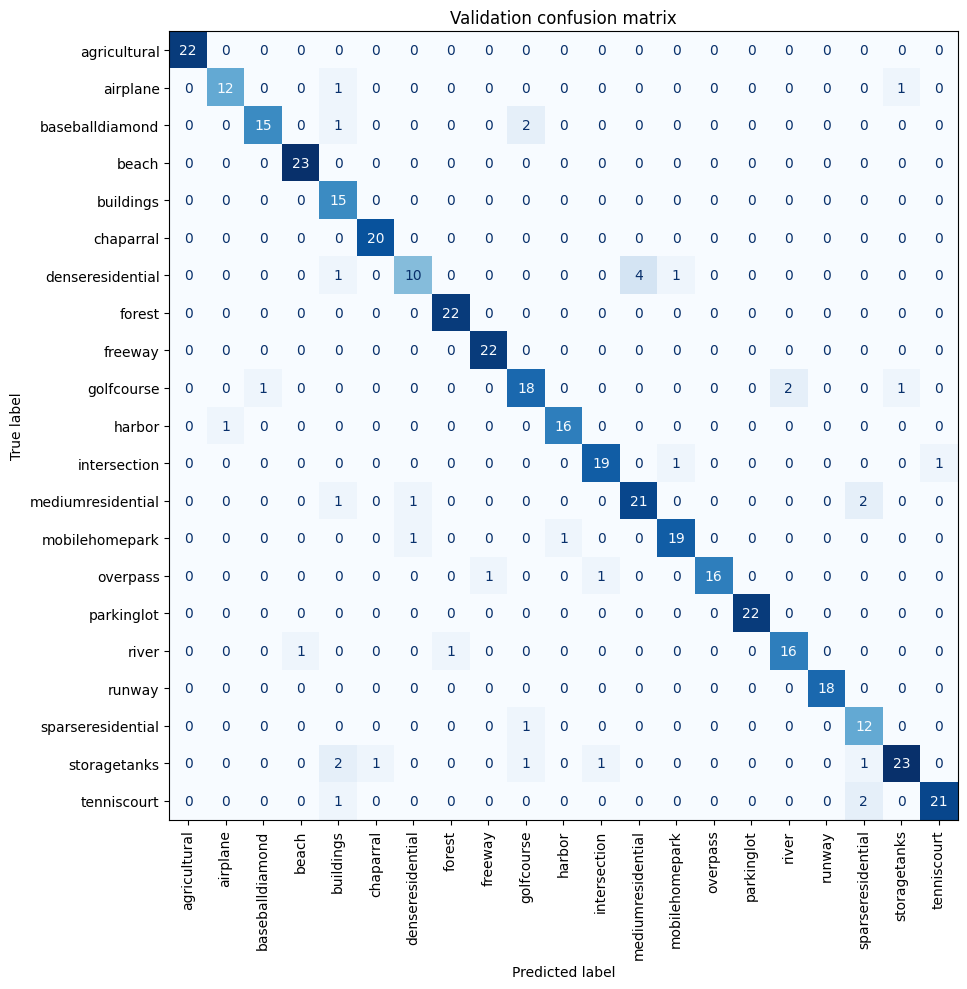

In [12]:
# Confusion matrix on validation set

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

@torch.no_grad()
def get_predictions(model, loader, device=DEVICE):
    model.eval()
    all_labels = []
    all_preds = []
    for images, labels in loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_labels.extend(labels.numpy().tolist())
        all_preds.extend(preds.cpu().numpy().tolist())
    return np.array(all_labels), np.array(all_preds)


val_labels_np, val_preds_np = get_predictions(model, val_loader)
cm = confusion_matrix(val_labels_np, val_preds_np, labels=list(range(len(class_names))))

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("Validation confusion matrix")
plt.tight_layout()
plt.show()


In [ ]:
# Experiment: training CNN-MLP WITHOUT data augmentation (resize + normalize only)

# Define no-augmentation transforms
noaug_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Build a fresh ImageFolder with no-augmentation transform
full_dataset_noaug = datasets.ImageFolder(IMAGES_ROOT, transform=noaug_transforms)

num_samples_noaug = len(full_dataset_noaug)
num_train_noaug = int(0.8 * num_samples_noaug)
num_val_noaug = num_samples_noaug - num_train_noaug

train_dataset_noaug, val_dataset_noaug = random_split(full_dataset_noaug, [num_train_noaug, num_val_noaug])

train_loader_noaug = DataLoader(train_dataset_noaug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=pin_memory)
val_loader_noaug = DataLoader(val_dataset_noaug, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=pin_memory)

print(f"[NO-AUG] Total images: {num_samples_noaug} | Train: {num_train_noaug} | Val: {num_val_noaug}")


In [14]:
# Train a new CNN-MLP model on the NO-AUG data and compare with the augmented model

EPOCHS_NOAUG = EPOCHS  # use the same number of epochs for fair comparison

model_noaug = CNNMLP().to(DEVICE)
criterion_noaug = nn.CrossEntropyLoss()
optimizer_noaug = torch.optim.Adagrad(
    filter(lambda p: p.requires_grad, model_noaug.parameters()), lr=1e-3
)

history_noaug = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

start_time_noaug = time.time()
for epoch in range(1, EPOCHS_NOAUG + 1):
    train_loss, train_acc = train_one_epoch(model_noaug, train_loader_noaug, optimizer_noaug, criterion_noaug)
    val_loss, val_acc = evaluate(model_noaug, val_loader_noaug, criterion_noaug)

    history_noaug["train_loss"].append(train_loss)
    history_noaug["train_acc"].append(train_acc)
    history_noaug["val_loss"].append(val_loss)
    history_noaug["val_acc"].append(val_acc)

    print(
        f"[NO-AUG] Epoch {epoch:02d}/{EPOCHS_NOAUG} | "
        f"Train loss: {train_loss:.4f}, acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f}, acc: {val_acc:.4f}"
    )

elapsed_noaug = time.time() - start_time_noaug
print(f"[NO-AUG] Total training time: {elapsed_noaug/60:.2f} minutes")

print("\nFinal validation accuracy WITH augmentation : {:.4f}".format(history["val_acc"][-1]))
print("Final validation accuracy WITHOUT augmentation: {:.4f}".format(history_noaug["val_acc"][-1]))


/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


[NO-AUG] Epoch 01/10 | Train loss: 2.9841, acc: 0.1000 | Val loss: 2.8707, acc: 0.3476
[NO-AUG] Epoch 02/10 | Train loss: 2.8393, acc: 0.2381 | Val loss: 2.7635, acc: 0.4024
[NO-AUG] Epoch 03/10 | Train loss: 2.7374, acc: 0.3363 | Val loss: 2.6830, acc: 0.6333
[NO-AUG] Epoch 04/10 | Train loss: 2.6696, acc: 0.3958 | Val loss: 2.6004, acc: 0.6452
[NO-AUG] Epoch 05/10 | Train loss: 2.5906, acc: 0.4577 | Val loss: 2.5521, acc: 0.6952
[NO-AUG] Epoch 06/10 | Train loss: 2.5404, acc: 0.4881 | Val loss: 2.4950, acc: 0.7833
[NO-AUG] Epoch 07/10 | Train loss: 2.4833, acc: 0.5190 | Val loss: 2.4361, acc: 0.8262
[NO-AUG] Epoch 08/10 | Train loss: 2.4212, acc: 0.5750 | Val loss: 2.3758, acc: 0.7310
[NO-AUG] Epoch 09/10 | Train loss: 2.3933, acc: 0.5780 | Val loss: 2.3574, acc: 0.7738
[NO-AUG] Epoch 10/10 | Train loss: 2.3477, acc: 0.6036 | Val loss: 2.3063, acc: 0.7667
[NO-AUG] Total training time: 1.89 minutes

Final validation accuracy WITH augmentation : 0.9095
Final validation accuracy WITHOUT

In [18]:
# Optimizer comparison for MLP: Adagrad vs Adam (same architecture, same data augmentation)

# Train a fresh CNN-MLP model with Adam instead of Adagrad
EPOCHS_ADAM = EPOCHS

model_adam = CNNMLP().to(DEVICE)
criterion_adam = nn.CrossEntropyLoss()
optimizer_adam = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_adam.parameters()), lr=1e-3
)

history_adam = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

start_time_adam = time.time()
for epoch in range(1, EPOCHS_ADAM + 1):
    train_loss, train_acc = train_one_epoch(model_adam, train_loader, optimizer_adam, criterion_adam)
    val_loss, val_acc = evaluate(model_adam, val_loader, criterion_adam)

    history_adam["train_loss"].append(train_loss)
    history_adam["train_acc"].append(train_acc)
    history_adam["val_loss"].append(val_loss)
    history_adam["val_acc"].append(val_acc)

    print(
        f"[ADAM] Epoch {epoch:02d}/{EPOCHS_ADAM} | "
        f"Train loss: {train_loss:.4f}, acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f}, acc: {val_acc:.4f}"
    )

elapsed_adam = time.time() - start_time_adam
print(f"[ADAM] Total training time: {elapsed_adam/60:.2f} minutes")

print("\nFinal validation accuracy with Adagrad (baseline MLP):   {:.4f}".format(history["val_acc"][-1]))
print("Final validation accuracy with Adam (alternative MLP): {:.4f}".format(history_adam["val_acc"][-1]))



/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


[ADAM] Epoch 01/10 | Train loss: 2.4238, acc: 0.4210 | Val loss: 1.6652, acc: 0.7071
[ADAM] Epoch 02/10 | Train loss: 1.2170, acc: 0.8038 | Val loss: 0.8786, acc: 0.8571
[ADAM] Epoch 03/10 | Train loss: 0.7092, acc: 0.8728 | Val loss: 0.5967, acc: 0.8667
[ADAM] Epoch 04/10 | Train loss: 0.5005, acc: 0.9014 | Val loss: 0.4763, acc: 0.8690
[ADAM] Epoch 05/10 | Train loss: 0.3805, acc: 0.9181 | Val loss: 0.4047, acc: 0.8929
[ADAM] Epoch 06/10 | Train loss: 0.3283, acc: 0.9250 | Val loss: 0.3957, acc: 0.8762
[ADAM] Epoch 07/10 | Train loss: 0.2615, acc: 0.9401 | Val loss: 0.3597, acc: 0.8929
[ADAM] Epoch 08/10 | Train loss: 0.2227, acc: 0.9500 | Val loss: 0.3085, acc: 0.9000
[ADAM] Epoch 09/10 | Train loss: 0.1962, acc: 0.9567 | Val loss: 0.3011, acc: 0.9143
[ADAM] Epoch 10/10 | Train loss: 0.1726, acc: 0.9617 | Val loss: 0.3085, acc: 0.8976
[ADAM] Total training time: 6.89 minutes

Final validation accuracy with Adagrad (baseline MLP):   0.9095
Final validation accuracy with Adam (alterna

In [19]:
# Fine-tuning experiment: unfreeze last layers of Xception with Adam optimizer

# Helper to unfreeze last N backbone blocks (approximate "last 10 layers")
def unfreeze_last_backbone_blocks(model, n_blocks=10):
    modules = list(model.backbone.children())
    for block in modules[-n_blocks:]:
        for p in block.parameters():
            p.requires_grad = True


# Load the best baseline CNN-MLP (trained with Adagrad, frozen backbone)
checkpoint_path = DATA_ROOT / "cnn_mlp_xception_best.pt"
print("Loading baseline checkpoint from", checkpoint_path)
ckpt = torch.load(checkpoint_path, map_location=DEVICE)

model_finetune = CNNMLP().to(DEVICE)
model_finetune.load_state_dict(ckpt["model_state"])

# Unfreeze the last few backbone blocks for fine-tuning
unfreeze_last_backbone_blocks(model_finetune, n_blocks=10)

# Use Adam with a small learning rate for fine-tuning
criterion_ft = nn.CrossEntropyLoss()
optimizer_ft = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_finetune.parameters()), lr=1e-5
)

EPOCHS_FT = 5  # small number of fine-tuning epochs
history_ft = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

start_time_ft = time.time()
for epoch in range(1, EPOCHS_FT + 1):
    train_loss, train_acc = train_one_epoch(model_finetune, train_loader, optimizer_ft, criterion_ft)
    val_loss, val_acc = evaluate(model_finetune, val_loader, criterion_ft)

    history_ft["train_loss"].append(train_loss)
    history_ft["train_acc"].append(train_acc)
    history_ft["val_loss"].append(val_loss)
    history_ft["val_acc"].append(val_acc)

    print(
        f"[FT] Epoch {epoch:02d}/{EPOCHS_FT} | "
        f"Train loss: {train_loss:.4f}, acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f}, acc: {val_acc:.4f}"
    )

elapsed_ft = time.time() - start_time_ft
print(f"[FT] Total fine-tuning time: {elapsed_ft/60:.2f} minutes")

print("\nBaseline validation accuracy (frozen backbone, Adagrad):   {:.4f}".format(history["val_acc"][-1]))
print("Fine-tuned validation accuracy (partly unfrozen, Adam): {:.4f}".format(history_ft["val_acc"][-1]))



Loading baseline checkpoint from data/uc_merced/cnn_mlp_xception_best.pt
[FT] Epoch 01/5 | Train loss: 0.3170, acc: 0.9423 | Val loss: 0.3430, acc: 0.9095
[FT] Epoch 02/5 | Train loss: 0.2541, acc: 0.9579 | Val loss: 0.3051, acc: 0.9214
[FT] Epoch 03/5 | Train loss: 0.2185, acc: 0.9671 | Val loss: 0.2890, acc: 0.9167
[FT] Epoch 04/5 | Train loss: 0.1892, acc: 0.9742 | Val loss: 0.2626, acc: 0.9286
[FT] Epoch 05/5 | Train loss: 0.1619, acc: 0.9825 | Val loss: 0.2536, acc: 0.9310
[FT] Total fine-tuning time: 4.09 minutes

Baseline validation accuracy (frozen backbone, Adagrad):   0.9095
Fine-tuned validation accuracy (partly unfrozen, Adam): 0.9310


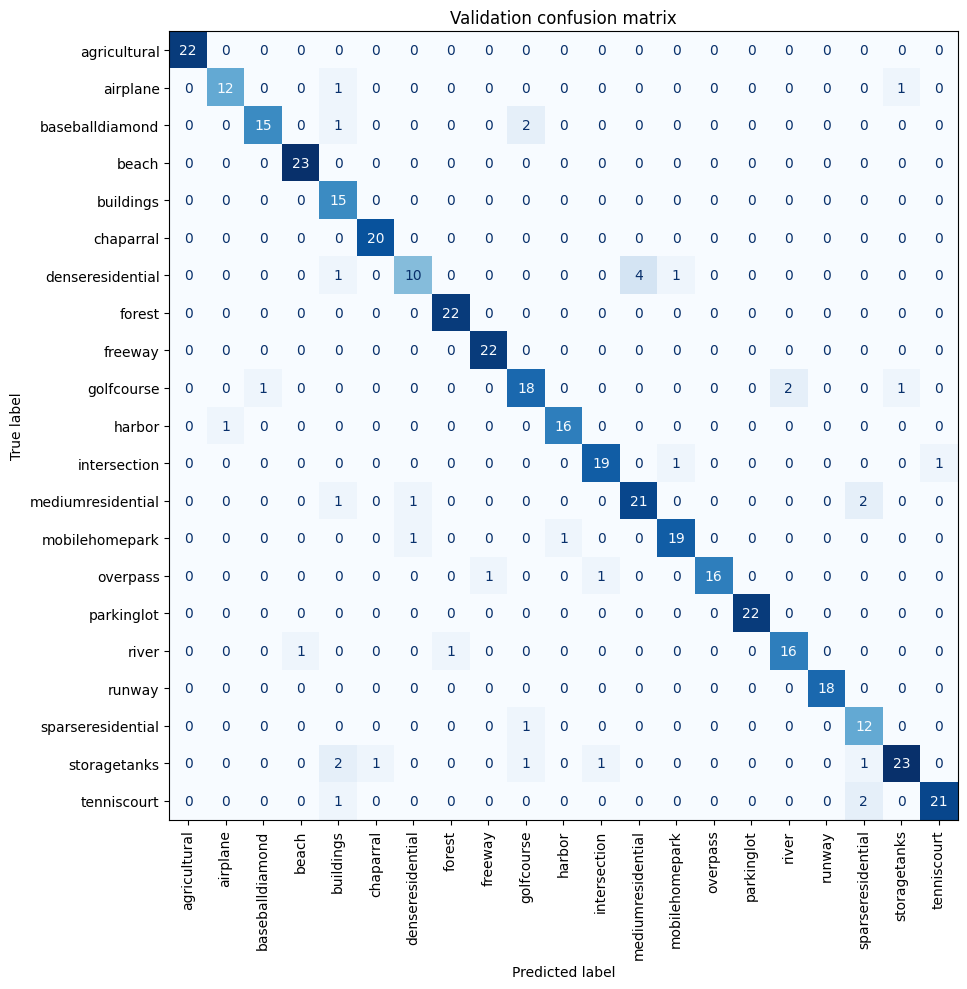

In [20]:
# Confusion matrix on validation set

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

@torch.no_grad()
def get_predictions(model, loader, device=DEVICE):
    model.eval()
    all_labels = []
    all_preds = []
    for images, labels in loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_labels.extend(labels.numpy().tolist())
        all_preds.extend(preds.cpu().numpy().tolist())
    return np.array(all_labels), np.array(all_preds)


val_labels_np, val_preds_np = get_predictions(model, val_loader)
cm = confusion_matrix(val_labels_np, val_preds_np, labels=list(range(len(class_names))))

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("Validation confusion matrix")
plt.tight_layout()
plt.show()
